# 1 · Phase 2 full raw preparation before preprocessing experiments

Run top to bottom before notebook 2. The default prepares **all available official
train images**, with a deterministic 80/20 train/tune split, using the existing
BDD100K/Scalabel → COCO → native YOLO conversion. Raw images remain source links.

Official val IDs are reserved after excluding Phase 1 exposures. Their pixels are
**not decoded, hashed, exported, previewed or evaluated** in this development run.
Annotation discovery is permitted for reservation; EDA and preflight use official
train only. Final holdout preparation needs a separate fresh run root after the
protocol, preprocessing recipes and model choices have been frozen on train/tune.


In [1]:
import importlib.metadata as md
import inspect
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from vehicle_detection.common import digest, read_image, read_json, write_json
from vehicle_detection.data import (
    ALIASES,
    CLASSES,
    audit_dataset,
    choose_splits,
    convert_labels,
    scan_bdd,
)
from vehicle_detection.offline import estimate_disk, export_variant, verify_alignment
from vehicle_detection.preprocess import apply_recipe, quality, validate_recipes

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
DATA_ROOT = ROOT / "data/bdd100k"
MODE = "full"  # 'full' selects all eligible examples; assess disk space first.
SEED = 2026
LIMITS = (
    {"train": 64, "tune": 16, "test": 16}
    if MODE == "pilot"
    else dict.fromkeys(["train", "tune", "test"])
)
RUN_ROOT = ROOT / "runs" / f"phase2-{MODE}"
OUTPUT_FORMAT = "jpg"  # Optional explicit alternative: "png" (use a fresh RUN_ROOT).
JPEG_QUALITY = 95
ENABLED_VARIANTS = ["raw_original"]  # Complete the full raw baseline first.
PREPARE_HOLDOUT = False  # Release only after train/tune experiments and protocol freeze.
# raw_reencoded is the JPEG95-only control; gamma uses exactly the same encoding.
PREFLIGHT_SAMPLE_SIZE = 128
DISK_SAMPLE_SIZE = 16
SOURCE_BOX_CONVENTION = "continuous"  # Explicit x2-x1 extents for this 2018-label study.
RECIPES = {
    "raw": {},
    "gamma": {"gamma": 0.65},
    "clahe": {"clip_limit": 2.0, "grid_size": 8},
    "denoise": {"strength": 5.0},
    "sharpen": {"amount": 0.5, "sigma": 1.0},
    "adaptive": {
        "brightness_below": 0.28,
        "contrast_below": 0.16,
        "noise_above": 0.035,
        "sharpness_min": 10.0,
        "sharpness_below": 100.0,
        "max_filters": 2,
    },
}
validate_recipes(RECIPES)
assert "raw_original" in ENABLED_VARIANTS
assert set(ENABLED_VARIANTS) <= (RECIPES.keys() - {"raw"}) | {"raw_original", "raw_reencoded"}
RUN_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
display(
    pd.Series(
        {
            p: md.version(p)
            for p in [
                "bdd100k",
                "scalabel",
                "pydantic",
                "ultralytics",
                "numpy",
                "opencv-python",
                "pandas",
            ]
        },
        name="installed version",
    )
)

bdd100k              1.0.1
scalabel             0.3.1
pydantic           1.10.27
ultralytics        8.4.198
numpy                2.4.6
opencv-python    4.14.0.94
pandas               2.3.3
Name: installed version, dtype: object

## Discover the real schema and canonical images

The local Kaggle extraction also contains 10k/segmentation copies. We deliberately
index **one canonical `images/100k` tree** and stream the split JSONs (the train
file is about 1.45 GB). Supported containers are the BDD 2018 frame list and modern
Scalabel `{frames: [...]}`. Missing files are counted; missing detection labels,
ambiguous paths and duplicate IDs fail. Person/rider/sign/light/polygon labels are
excluded from this six-vehicle study. Occluded/truncated vehicle boxes are kept.
The actual execution below verifies the 2018 file; a 2020 container is covered by
a small fixture test, **not** claimed as a separate real-data run.

In [2]:
records, audit, annotation_sources = scan_bdd(DATA_ROOT)
print("Detection frames with matching images:", len(records))
display(pd.DataFrame(annotation_sources).T)
display(pd.Series(audit, name="discovery audit"))
print("Frame fields:", list(records[0]))
print("Actual first retained box label:", records[0]["labels"][0])
# Keep official-val records for ID reservation only; all diagnostics use official train.
training_records = [r for r in records if r["official_split"] == "train"]

Detection frames with matching images: 79863


,path,sha256,schema
train,/mnt/d/Projects/vehicle-detection/data/bdd100k...,c1998792e385fd79213187576ca07d5249563d0ab83ae9...,item
val,/mnt/d/Projects/vehicle-detection/data/bdd100k...,c835be652f0c002897be51e74deedd16a1dcee0b7230f1...,item


frames:train                              69863
ignored_nonvehicle_or_polygon_labels    1345450
frames:val                                10000
missing_image_examples                       []
Name: discovery audit, dtype: object

Frame fields: ['id', 'name', 'path', 'official_split', 'group', 'attributes', 'labels']
Actual first retained box label: {'category': 'car', 'attributes': {'occluded': False, 'truncated': False, 'trafficLightColor': 'none'}, 'manualShape': True, 'manualAttributes': True, 'box2d': {'x1': 45.240919, 'y1': 254.530367, 'x2': 357.805838, 'y2': 487.906215}, 'id': 4}


split,train
vehicle box counts,
car,713211
truck,29971
bus,11672
train,136
motorcycle,3002
bicycle,7210


split,train
images containing class,
car,69072
truck,18890
bus,8993
train,105
motorcycle,2284
bicycle,4343


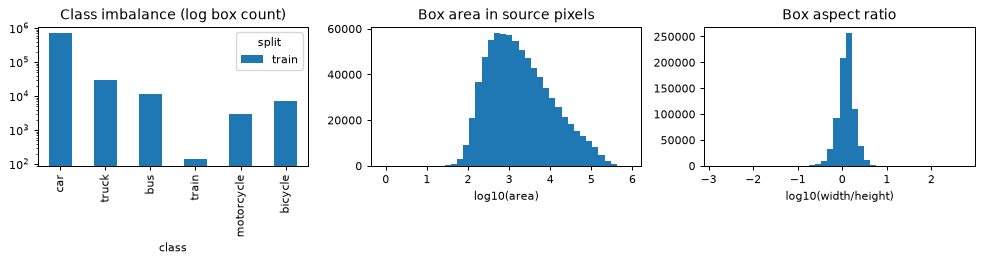

In [3]:
images = pd.DataFrame(
    [
        {
            "id": r["id"],
            "split": r["official_split"],
            **{k: r["attributes"].get(k, "unknown") for k in ["weather", "timeofday", "scene"]},
        }
        for r in training_records
    ]
)
boxes = pd.DataFrame(
    [
        {
            "id": r["id"],
            "split": r["official_split"],
            "class": ALIASES.get(label["category"], label["category"]),
            "width": label["box2d"]["x2"] - label["box2d"]["x1"],
            "height": label["box2d"]["y2"] - label["box2d"]["y1"],
        }
        for r in training_records
        for label in r["labels"]
    ]
)
boxes["area"] = boxes.width * boxes.height
boxes["aspect_ratio"] = boxes.width / boxes.height
counts = pd.crosstab(boxes["class"], boxes["split"]).reindex(CLASSES, fill_value=0)
display(counts.rename_axis("vehicle box counts"))
display(
    boxes.groupby(["split", "class"])
    .id.nunique()
    .unstack(0)
    .reindex(CLASSES)
    .fillna(0)
    .astype(int)
    .rename_axis("images containing class")
)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
counts.plot.bar(ax=axes[0], logy=True, title="Class imbalance (log box count)")
axes[1].hist(np.log10(boxes.loc[boxes.area > 0, "area"]), bins=40)
axes[1].set(title="Box area in source pixels", xlabel="log10(area)")
axes[2].hist(np.log10(boxes.loc[boxes.aspect_ratio > 0, "aspect_ratio"]), bins=40)
axes[2].set(title="Box aspect ratio", xlabel="log10(width/height)")
fig.tight_layout()
plt.show()

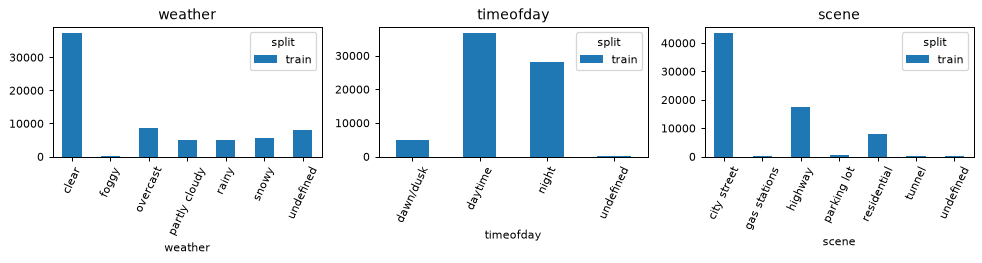

,brightness,contrast,sharpness,noise,black_fraction,white_fraction
count,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
mean,0.2813,0.1827,562.7849,0.0007,0.0394,0.0041
std,0.1579,0.0626,380.3018,0.0019,0.0875,0.0098
min,0.0440,0.0609,40.3137,0.0000,0.0000,0.0000
25%,0.1159,0.1279,248.7247,0.0000,0.0000,0.0001
50%,0.3504,0.1969,452.9902,0.0000,0.0012,0.0011
75%,0.4212,0.2286,835.8628,0.0000,0.0212,0.0036
max,0.6345,0.3130,1507.5540,0.0058,0.4339,0.0607


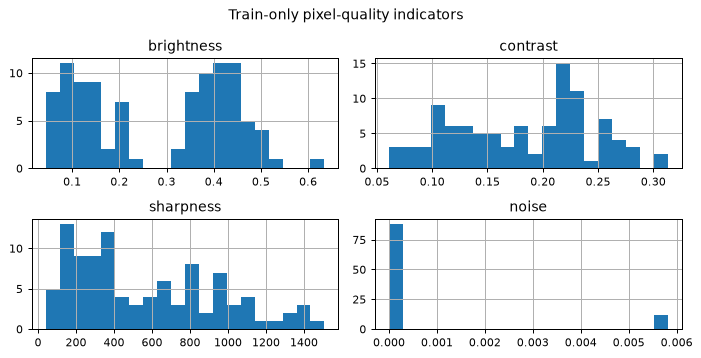

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, key in zip(axes, ["weather", "timeofday", "scene"], strict=True):
    pd.crosstab(images[key], images.split).plot.bar(ax=ax, title=key)
    ax.tick_params(axis="x", rotation=65)
fig.tight_layout()
plt.show()
train_records = training_records
sampled = pd.Series(train_records).sample(min(100, len(train_records)), random_state=SEED).tolist()
quality_table = pd.DataFrame([{"id": r["id"], **quality(read_image(r["path"]))} for r in sampled])
display(quality_table.describe().round(4))
quality_table[["brightness", "contrast", "sharpness", "noise"]].hist(bins=20, figsize=(8, 4))
plt.suptitle("Train-only pixel-quality indicators")
plt.tight_layout()
plt.show()

Quality is measured at a maximum 512-pixel side: grayscale mean and standard
deviation divided by 255, Laplacian variance, and median absolute residual against
a 3×3 median filter divided by 0.6745×255. Texture can affect these indicators.
Adaptive thresholds are transparent **uncalibrated heuristics**. A bounded
sequence (maximum two filters) or skip is chosen from pixels, never BDD metadata.
No filter changes image coordinates, and sharpening cannot recover lost blur detail.

Quality diagnostics sample official train only; recipe previews below use train-derived tune. Neither is calibrated from official-val test pixels.

## Full train-only preflight and disk budget

All supplied training image headers and vehicle boxes are audited before conversion.
Missing images fail full mode; no invalid box is clipped. Official-val image pixels
remain reserved. The sampled disk estimate covers only the selected exports;
raw-original links add no copied image bytes. Labels, weights and caches need extra space.

In [5]:
import shutil

audit_input = (
    training_records
    if MODE == "full"
    else pd.Series(training_records)
    .sample(min(PREFLIGHT_SAMPLE_SIZE, len(training_records)), random_state=SEED)
    .tolist()
)
preflight = audit_dataset(audit_input, SOURCE_BOX_CONVENTION)
write_json(RUN_ROOT / "preflight.json", preflight)
display(pd.Series(preflight["counts"], name="header / annotation counts"))
display(preflight["errors"])
display(preflight["examples"])
print("Audit scope:", preflight["scope"])
missing = audit.get("missing_images:train", 0)
if MODE == "full" and (preflight["error_count"] or missing):
    raise ValueError(
        "Full-run preflight failed: inspect counts/IDs and curate inputs; no clipping is performed"
    )
excluded_full = set().union(*read_json(ROOT / "notebooks/test_exposure.json").values())
eligible = sum(r["official_split"] == "train" or r["id"] not in excluded_full for r in records)
planned_count = (
    (eligible if PREPARE_HOLDOUT else len(training_records))
    if MODE == "full"
    else sum(LIMITS.values())
)
disk_sample = (
    pd.Series(train_records)
    .sample(min(DISK_SAMPLE_SIZE, len(train_records)), random_state=SEED)
    .tolist()
)
disk_budget = estimate_disk(
    disk_sample,
    planned_count,
    ENABLED_VARIANTS,
    RECIPES,
    output_format=OUTPUT_FORMAT,
    jpeg_quality=JPEG_QUALITY,
)
disk_budget.to_csv(RUN_ROOT / "disk_estimate.csv", index=False)
display(disk_budget.round(4))
free_gib = shutil.disk_usage(RUN_ROOT).free / 2**30
print("Free disk GiB:", round(free_gib, 2), "format:", OUTPUT_FORMAT, "JPEG quality:", JPEG_QUALITY)
if MODE == "full" and disk_budget.p90_budget_GiB.sum() * 1.1 > free_gib:
    raise ValueError("Estimated full export plus 10% headroom exceeds free disk")

images               69863
boxes               765202
readable_headers     69863
valid_boxes         765202
Name: header / annotation counts, dtype: int64

{}

{}

Audit scope: all supplied boxes and image headers; no full-pixel decode or content hashes


,variant,sample_images,planned_images,mean_bytes_per_image,estimated_GiB,p90_budget_GiB
0,raw_original,16,69863,0.0,0.0,0.0


Free disk GiB: 578.72 format: jpg JPEG quality: 95


In [6]:
exposure_path = ROOT / "notebooks/test_exposure.json"
exposure = read_json(exposure_path)
excluded = set(exposure["legacy_pilot"])
if MODE == "full":
    excluded.update(exposure["notebook_pilot"])
partitions = choose_splits(
    records, SEED, LIMITS, excluded_test_ids=excluded, prepare_test=PREPARE_HOLDOUT
)
selection = {s: [r["id"] for r in rows] for s, rows in partitions.items()}
selection_id = digest(
    [(s, r["id"], r["sha256"], r["labels"]) for s, rows in partitions.items() for r in rows]
)
study = {
    "seed": SEED,
    "limits": LIMITS,
    "selection_id": selection_id,
    "splits": selection,
    "excluded_test_ids": sorted(excluded),
    "box_convention": SOURCE_BOX_CONVENTION,
    "annotation_sources": annotation_sources,
    "holdout_prepared": PREPARE_HOLDOUT,
    "reserved_test_ids": sorted(
        r["id"] for r in records if r["official_split"] == "val" and r["id"] not in excluded
    ),
}
study_path = RUN_ROOT / "selection.json"
if study_path.exists() and read_json(study_path) != study:
    raise ValueError("Selection/config changed: use a fresh RUN_ROOT")
write_json(study_path, study)
if MODE == "pilot" and PREPARE_HOLDOUT:
    exposure["notebook_pilot"] = sorted(set(exposure["notebook_pilot"]) | set(selection["test"]))
    write_json(exposure_path, exposure)
display(pd.Series({s: len(v) for s, v in partitions.items()}, name="selected images"))
print(
    "Disjoint ID/video-group/content hashes checked; excluded previously exposed test IDs:",
    len(excluded),
)

train    55890
tune     13973
Name: selected images, dtype: int64

Disjoint ID/video-group/content hashes checked; excluded previously exposed test IDs: 96


## Official conversion, explicit coordinate bridge, exhaustive selected-box checks

The pinned **BDD100K 1.0.1** API uses `bdd100k_to_scalabel` for its official
`bike→bicycle`, `motor→motorcycle` mapping, then the detection converter imported
by `bdd100k.label.to_coco`. It accepts the local 2018 list through Scalabel's
validated loader. Only selected box labels are passed, avoiding 2018 lane polygons
and loading the entire giant JSON. Actual decoded dimensions are attached per frame.

**Version incompatibility:** Scalabel **0.3.1** computes `x2-x1+1`. This study uses
continuous BDD2018 extents `x2-x1`; the minimal adapter subtracts that added one
from official COCO width/height and recomputes area. `inclusive` can be selected
explicitly for a dataset defined that way. No clipping/scaling is performed.
The six official COCO category IDs are remapped to 1–6 by name, then native
`convert_coco(..., cls91to80=False)` makes YOLO IDs 0–5. Native crowd/ignored
annotations are excluded and identical boxes are deduplicated. Every selected
YOLO box is decoded and checked against its source to **0.01 pixel**; IDs/bounds
must be valid. Labels with no vehicles remain valid empty files.

References: [BDD toolkit](https://github.com/bdd100k/bdd100k),
[Scalabel converter](https://github.com/scalabel/scalabel/blob/v0.3.1/scalabel/label/transforms.py),
[Ultralytics converter](https://docs.ultralytics.com/reference/data/converter/).

In [7]:
from bdd100k.label.to_coco import scalabel2coco_detection
from scalabel.label.transforms import box2d_to_bbox

print(inspect.getsource(box2d_to_bbox))
print("Official detection API:", inspect.signature(scalabel2coco_detection))
conversion = convert_labels(partitions, RUN_ROOT / "conversion", SOURCE_BOX_CONVENTION)
display(conversion)
display(pd.DataFrame({"class": CLASSES, "COCO ID": range(1, 7), "YOLO ID": range(6)}))

def box2d_to_bbox(box2d: Box2D) -> List[float]:
    """Convert Scalabel Box2D into COCO bbox."""
    width = box2d.x2 - box2d.x1 + 1
    height = box2d.y2 - box2d.y1 + 1
    return [box2d.x1, box2d.y1, width, height]

Official detection API: (frames: List[scalabel.label.typing.Frame], config: scalabel.label.typing.Config) -> scalabel.label.coco_typing.GtType


  0%|          | 0/55890 [00:00<?, ?it/s]

 43%|████▎     | 24192/55890 [00:00<00:00, 241901.20it/s]

 88%|████████▊ | 49187/55890 [00:00<00:00, 246621.25it/s]

100%|██████████| 55890/55890 [00:00<00:00, 245250.91it/s]

  0%|          | 0/55890 [00:00<?, ?it/s]

... (2,363 outputs left out)

Annotations /mnt/d/Projects/vehicle-detection/runs/phase2-full/conversion/coco/tune.json: 99% ━━━━━━━━━━━╸ 13786/13842 296.0it/s 47.6s<0.2s

Annotations /mnt/d/Projects/vehicle-detection/runs/phase2-full/conversion/coco/tune.json: 99% ━━━━━━━━━━━╸ 13816/13842 296.0it/s 47.7s<0.1s

Annotations /mnt/d/Projects/vehicle-detection/runs/phase2-full/conversion/coco/tune.json: 100% ━━━━━━━━━━━━ 13842/13842 289.7it/s 47.8s

COCO data converted successfully.
Results saved to /mnt/d/Projects/vehicle-detection/runs/phase2-full/conversion/tmpjslbfkz1/yolo


In [ ]:
from ultralytics.utils.ops import xywh2xyxy


def overlay(image, record=None, label_path=None):
    image = image.copy()
    if record is not None:
        # Explicit key order; JSON dictionary order is not a coordinate contract.
        annotations = [
            (
                ALIASES.get(label["category"], label["category"]),
                [label["box2d"][k] for k in ["x1", "y1", "x2", "y2"]],
            )
            for label in record["labels"]
        ]
    else:
        text = Path(label_path).read_text().strip()
        labels = np.loadtxt(label_path, ndmin=2).reshape(-1, 5) if text else np.empty((0, 5))
        h, w = image.shape[:2]
        xyxy = xywh2xyxy(labels[:, 1:] * np.array([w, h, w, h]))
        annotations = [(CLASSES[int(row[0])], box) for row, box in zip(labels, xyxy, strict=True)]
    for name, box in annotations:
        x1, y1, x2, y2 = map(round, box)
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(image, name, (x1, max(12, y1)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


example = next(r for r in partitions["tune"] if r["labels"])
label_path = RUN_ROOT / "conversion/labels/tune" / f"{example['id']}.txt"
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(overlay(read_image(example["path"]), record=example))
axes[0].set_title("Original 2018 box geometry")
axes[1].imshow(overlay(read_image(example["path"]), label_path=label_path))
axes[1].set_title("Native converted YOLO labels")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

## Inspect recipes before materializing full datasets

These previews use only **tune** images. Raw/fixed/adaptive pixel recipes are configurable
above; disabled variants generate no image copies. The adaptive policy may select
no filters. Generated exports use the selected encoding (default JPEG95); `raw_original` links source JPEG bytes, while `raw_reencoded` uses the same encoder as gamma. Compare gamma against that control, not only the source originals. Changing recipes or selected inputs requires a fresh output directory.

In [ ]:
preview = read_image(example["path"])
fig, axes = plt.subplots(2, 3, figsize=(9, 5))
preview_rows = []
for ax, variant in zip(axes.flat, RECIPES, strict=True):
    processed, decisions, scores = apply_recipe(preview, variant, RECIPES)
    ax.imshow(overlay(processed, label_path=label_path))
    ax.axis("off")
    ax.set_title(variant)
    preview_rows.append({"variant": variant, "decisions": decisions, **quality(processed)})
fig.suptitle("Tune-only previews · identical converted GT boxes")
fig.tight_layout()
plt.show()
display(pd.DataFrame(preview_rows).set_index("variant"))
pd.DataFrame(preview_rows).set_index("variant")[["brightness", "contrast", "noise"]].plot.bar(
    figsize=(8, 3), title="Tune image quality after each recipe"
)
plt.tight_layout()
plt.show()

In [ ]:
started = time.perf_counter()
tables = []
for variant in ENABLED_VARIANTS:
    table = export_variant(
        partitions,
        RUN_ROOT / "conversion",
        RUN_ROOT / "datasets" / variant,
        variant,
        RECIPES,
        output_format=OUTPUT_FORMAT,
        jpeg_quality=JPEG_QUALITY,
    )
    tables.append(table)
    print(variant, "images:", len(table), "verified reused:", int(table.reused.sum()))
metadata = pd.concat(tables, ignore_index=True)
assert verify_alignment([RUN_ROOT / "datasets" / v for v in ENABLED_VARIANTS]) == sum(
    map(len, partitions.values())
)
metadata.to_csv(RUN_ROOT / "metadata.csv", index=False)
preparation = metadata.groupby("variant").agg(
    images=("id", "size"),
    preprocess_ms=("preprocess_ms", "sum"),
    preparation_ms=("preparation_ms", "sum"),
)
preparation["output_MiB"] = metadata.groupby("variant").apply(
    lambda d: sum(Path(p).stat().st_size for p in d.image if not Path(p).is_symlink()) / 2**20,
    include_groups=False,
)
preparation["logical_image_MiB"] = metadata.groupby("variant").apply(
    lambda d: sum(Path(p).stat().st_size for p in d.image) / 2**20, include_groups=False
)
preparation.to_csv(RUN_ROOT / "preparation_cost.csv")
display(preparation.round(3))
display(metadata[["id", "split", "variant", "decisions", "preprocess_ms", "reused"]].head(8))
print("Export wall seconds:", round(time.perf_counter() - started, 3))

## Compression control: source original / JPEG95-only / gamma+JPEG95

`raw_original` is the untouched source reference. `raw_reencoded` and gamma use
identical format/quality settings. A raw-original vs gamma-JPEG difference contains
both filtering and re-encoding effects; the re-encoded raw control is necessary to
separate them. The following are actual decoded exports with the same GT boxes.
Image sizes are logical bytes; source links consume no copied-image storage.

In [ ]:
comparison_variants = ENABLED_VARIANTS
examples = [r for r in partitions["tune"] if r["labels"]][:2]
fig, axes = plt.subplots(
    len(examples),
    len(comparison_variants),
    figsize=(4 * len(comparison_variants), 3 * len(examples)),
    squeeze=False,
)
compression_rows = []
for i, r in enumerate(examples):
    for j, variant in enumerate(comparison_variants):
        row = metadata[(metadata.id == r["id"]) & (metadata.variant == variant)].iloc[0]
        image_path = Path(row.image)
        labels = RUN_ROOT / "datasets" / variant / "labels/tune" / f"{r['id']}.txt"
        axes[i, j].imshow(overlay(read_image(image_path), label_path=labels))
        axes[i, j].axis("off")
        axes[i, j].set_title(f"{variant} · {image_path.stat().st_size / 1024:.1f} KiB")
        compression_rows.append(
            {
                "id": r["id"],
                "variant": variant,
                "bytes": image_path.stat().st_size,
                "format": "source original" if variant == "raw_original" else OUTPUT_FORMAT,
                "jpeg_quality": None
                if variant == "raw_original" or OUTPUT_FORMAT != "jpg"
                else JPEG_QUALITY,
            }
        )
fig.tight_layout()
plt.show()
display(pd.DataFrame(compression_rows))

Preparation time is an **offline cost**: read/decode, quality/filter work, image and
label writes, and output checks. `preprocess_ms` isolates feature/filter work.
The saved per-image times describe the original materialization, not a reuse run.
They must not be added to native validation speed and described as a measured online
end-to-end pipeline. Source hashing/discovery/conversion and reuse verification add
separate notebook wall time. Full PNG variants can use substantial disk space.

Exports use one compact JSONL metadata journal per variant and a CSV table, not
prediction shards. Recipe/input identities reject incompatible reruns. Completed
images/labels are hash-verified; missing/corrupt generated outputs can be repaired.
Unexpected symlinks are rejected so repairs cannot overwrite source images.

In [ ]:
# Clean export reuse pass: no preprocessing or image writes should occur.
for variant in ENABLED_VARIANTS:
    reused = export_variant(
        partitions,
        RUN_ROOT / "conversion",
        RUN_ROOT / "datasets" / variant,
        variant,
        RECIPES,
        output_format=OUTPUT_FORMAT,
        jpeg_quality=JPEG_QUALITY,
    )
    assert reused.reused.all()
print("PASS: every completed image and label verified and reused")
assert verify_alignment([RUN_ROOT / "datasets" / v for v in ENABLED_VARIANTS]) == sum(
    map(len, selection.values())
)
print("PASS: all variants share exact IDs, label bytes, dimensions and splits")

**Next:** run notebook 2 for the full raw baseline. Do not expand exports while that
run is unfinished. After completion, use the same frozen raw checkpoint to calibrate
Gamma, CLAHE, Denoise, Sharpen and Adaptive on train/tune, with JPEG95-only control.
Use a fresh export root for a changed recipe or split identity. Final holdout release,
controlled benchmark and remaining research work are tracked under Issue #1.